# Etapa 5. Índice multidimensional y KNN exacto (KD-Tree)

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de las etapas 3, 4 y 5: Carlos.

## Función de la etapa en el pipeline

La etapa 5 resuelve las consultas sobre **varios atributos a la vez**. El escenario B pide generar productos similares a partir de sus atributos. El B+Tree de la etapa 4 ordena por una sola clave y no puede responder "los 10 productos más parecidos a este en precio, calificación y popularidad". Para eso cada producto se representa como un punto en un espacio de 4 dimensiones y se buscan sus k vecinos más cercanos (KNN).

La estructura es un **KD-Tree** implementado a mano. Responde dos tipos de consulta.

- **KNN exacto.** Los k productos más cercanos a uno dado, con un filtro opcional por categoría.
- **Rango multidimensional.** Los productos dentro de una caja, por ejemplo precio entre 10 y 20 dólares, calificación de al menos 4.5 y al menos 1 000 calificaciones.

El **KNN por fuerza bruta**, que calcula la distancia a todos los puntos, es la línea base exacta. La etapa 7 usa el KNN exacto de esta etapa como referencia para medir el recall@K de su búsqueda aproximada.

**KD-Tree o R-Tree.** El enunciado permite cualquiera de los dos según el escenario. Se elige el KD-Tree por tres razones.

- Los datos son **puntos**. El R-Tree está pensado para objetos con extensión, como rectángulos o polígonos, y agrupa sus cajas envolventes (Guttman, 1984).
- La dimensión es **baja** (d = 4), que es donde el KD-Tree poda bien (Friedman, Bentley y Finkel, 1977).
- El conjunto es **casi estático**. Se construye una vez desde el catálogo y recibe pocas inserciones. El R-Tree se justifica cuando las inserciones son frecuentes.

## Proceso

```
índice de precios (etapa 4) + catálogo en disco (etapa 3) + estado del stream (etapa 3)
   │
   ├─ 1. recorrer el B+Tree y leer el registro de cada producto con precio
   ├─ 2. construir el vector de 4 atributos y normalizarlo (z-score)
   ├─ 3. construir el KD-Tree: mediana de la dimensión de mayor dispersión   O(n log n)
   │
   ├─ KNN: descenso al lado de q, poda por distancia al hiperplano        ≈ O(log n) en dimensión baja
   └─ rango: descenso por los lados que cortan la caja
   │
vectores y vecinos exactos (etapas 7 y 9)
```

## Pasos del notebook

1. Configuración y entrada.
2. Vectores de productos.
3. KD-Tree propio.
4. Construcción del índice.
5. Consultas de productos similares y por rango.
6. Experimentos de complejidad.
7. Salida de la etapa 5.

El código está en `src/stage5_kdtree.py`. El notebook lo importa y muestra las partes principales.

## Paso 1. Configuración y entrada

La etapa usa tres salidas de las etapas anteriores, que están en `data/interim/<CATEGORIA>/`.

- `etapa4_indice_precio.bpt`, el índice de los productos con precio. Recorrer sus hojas enlazadas da los productos en orden de precio y la posición de cada registro.
- `etapa3_catalogo.jsonl`, el catálogo en disco, del que se leen la calificación, el número de calificaciones y la categoría.
- `etapa3_estado_productos.parquet`, la actividad de cada producto en el stream.

In [1]:
import gc
import inspect
import math
import platform
import random
import sys
import time
import tracemalloc
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import pyarrow as pa
import pyarrow.parquet as pq

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config
from src.stage4_bplustree import RUTA_INDICE_PRECIO, ArbolBMas
from src.stage5_kdtree import (ATRIBUTOS, RUTA_ESTADOS, RUTA_VECINOS, RUTA_VECTORES, TAM_HOJA, IndiceProductos,
                               KDTree, construir_vectores, knn_fuerza_bruta)

SEED = config.SEED
CATEGORIA = config.CATEGORIA
CARPETA_INTERIM = config.CARPETA_INTERIM
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS
CARPETA_RESULTADOS.mkdir(exist_ok=True)
assert RUTA_INDICE_PRECIO.exists(), "Falta la salida de la etapa 4. Ejecutar antes notebooks/etapa4_indexacion_bplustree.ipynb"
assert RUTA_ESTADOS.exists(), "Falta la salida de la etapa 3. Ejecutar antes notebooks/etapa3_almacenamiento_cache.ipynb"

PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}
print(f"Categoría: {CATEGORIA}")
pd.Series(PLATAFORMA).to_frame("plataforma")

Categoría: Office_Products


,plataforma
sistema,Windows-11-10.0.26200-SP0
procesador,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
nucleos,20
ram_gb,25.4
python,3.12.10
semilla,42


## Paso 2. Vectores de productos

Cada producto del índice de precios se representa con cuatro atributos.

| Atributo | Definición | Justificación |
| --- | --- | --- |
| `log_precio` | log(1 + precio) | Los precios van de 0.01 a 30 499 dólares. En escala logarítmica, 10 y 20 dólares están tan lejos como 100 y 200 |
| `average_rating` | Calificación promedio del catálogo, de 1 a 5 | Calidad percibida |
| `log_rating_number` | log(1 + número de calificaciones) | Popularidad histórica. La distribución tiene una cola larga |
| `log_actividad_stream` | log(1 + vistas + carritos + compras en el stream) | Popularidad reciente, registrada por la etapa 3 |

Cada atributo se normaliza con z-score (media 0 y desviación 1). Sin esa normalización el número de calificaciones, con desviación 1.9, pesaría casi el triple que la calificación, con desviación 0.66, en la distancia euclidiana.

La categoría de último nivel no entra en el vector porque no es numérica. Se usa como filtro, para buscar productos similares dentro de la misma categoría.

In [2]:
t0 = time.perf_counter()
asins, X_crudo, categorias, titulos = construir_vectores()
t_vectores = time.perf_counter() - t0
print(f"Vectores: {len(asins):,} productos × {X_crudo.shape[1]} atributos en {t_vectores:.1f} s")
print(f"Categorías de último nivel: {len(set(categorias)):,}")
print(f"Productos con actividad en el stream: {(X_crudo[:, 3] > 0).sum():,}")
pd.DataFrame(X_crudo, columns=ATRIBUTOS).describe().round(3)

Vectores: 336,415 productos × 4 atributos en 6.4 s
Categorías de último nivel: 607
Productos con actividad en el stream: 193,416


,log_precio,average_rating,log_rating_number,log_actividad_stream
count,336415.000,336415.000,336415.000,336415.000
mean,3.171,4.325,3.490,1.547
std,0.959,0.672,1.867,1.578
min,0.010,1.000,0.693,0.000
25%,2.441,4.100,1.946,0.000
50%,2.993,4.500,3.332,1.609
75%,3.761,4.700,4.745,2.565
max,10.325,5.000,12.284,9.313


## Paso 3. KD-Tree propio

Un KD-Tree es un árbol binario de búsqueda sobre puntos de d dimensiones (Bentley, 1975). Cada nodo interno divide su región en dos con un hiperplano perpendicular a una dimensión.

- **Dimensión de corte.** Se elige la de mayor dispersión dentro del nodo. Así las regiones quedan más cercanas a cubos que si se alternaran las dimensiones en orden fijo.
- **Valor de corte.** La mediana, obtenida con `np.argpartition` en O(m) para m puntos. Cada división deja dos mitades iguales, así que el árbol queda balanceado con altura log₂(n / tamaño de hoja). La construcción cuesta O(n log n).
- **Hojas.** Guardan hasta 32 puntos. Los puntos se reordenan para que cada hoja ocupe un tramo contiguo de un arreglo, y la distancia de la consulta a todos los puntos de una hoja se calcula con una operación de numpy.

**Búsqueda KNN.** Es un recorrido en profundidad que entra primero al lado del hiperplano donde está la consulta q. Los k mejores candidatos se guardan en el `MinHeap` de la etapa 2 con la distancia negada, así que la raíz del heap es el peor candidato y se consulta en O(1). Un subárbol se descarta si la distancia de q a su región ya no mejora al peor candidato. Con dimensión baja se visitan O(log n) nodos en promedio. El peor caso es O(n), cuando la poda no descarta nada, y eso ocurre cuando la dimensión es alta.

**Filtro por categoría.** En las hojas solo se aceptan puntos con la etiqueta pedida. La poda sigue siendo correcta, porque la cota de distancia no depende de la etiqueta.

**KD-Tree por categoría.** Con el filtro sobre el árbol global, los productos de una categoría pequeña están dispersos en todo el espacio y la búsqueda recorre muchas hojas hasta reunir k productos de esa categoría. Por eso `IndiceProductos` construye además un KD-Tree con los productos de cada una de las categorías. La consulta de productos similares dentro de la categoría usa ese árbol, que solo contiene sus productos. El filtro sobre el árbol global se mantiene para comparar los dos métodos en el paso 5. La construcción de todos los árboles por categoría cuesta O(n log n) en total, igual que la del árbol global.

In [3]:
print(inspect.getsource(KDTree._construir))
print(inspect.getsource(KDTree.knn))

    def _construir(self, lo, hi):
        nodo = len(self.dim)
        for lista in (self.dim, self.corte, self.izq, self.der, self.lo, self.hi):
            lista.append(-1)
        self.lo[nodo], self.hi[nodo] = lo, hi
        if hi - lo <= self.tam_hoja:
            return nodo                                # hoja: dim = -1
        indices = self.perm[lo:hi]
        puntos = self._X0[indices]
        dim = int(np.argmax(puntos.max(axis=0) - puntos.min(axis=0)))
        if puntos[:, dim].max() == puntos[:, dim].min():
            return nodo                                # todos los puntos son iguales: hoja grande
        mitad = (hi - lo) // 2
        orden = np.argpartition(puntos[:, dim], mitad)
        self.perm[lo:hi] = indices[orden]
        # La mitad izquierda queda con valores <= corte y la derecha con valores >= corte
        self.dim[nodo] = dim
        self.corte[nodo] = float(puntos[orden[mitad], dim])
        self.izq[nodo] = self._construir(lo, lo + mitad)
        se

## Paso 4. Construcción del índice

In [4]:
t0 = time.perf_counter()
indice = IndiceProductos(asins, X_crudo, categorias)
t_kd = time.perf_counter() - t0
kd = indice.kd
print(f"KD-Tree construido en {t_kd:.2f} s: {kd.n_nodos:,} nodos, altura {kd.altura()} "
      f"(log₂(n / {TAM_HOJA}) = {math.log2(kd.n / TAM_HOJA):.1f})")
print(f"Media de los atributos: {np.round(indice.media, 3).tolist()}")
print(f"Desviación de los atributos: {np.round(indice.desv, 3).tolist()}")

KD-Tree construido en 1.41 s: 32,737 nodos, altura 15 (log₂(n / 32) = 13.4)
Media de los atributos: [3.171, 4.325, 3.49, 1.547]
Desviación de los atributos: [0.959, 0.672, 1.867, 1.578]


## Paso 5. Consultas de productos similares y por rango

**Productos similares.** Se buscan los 5 vecinos más cercanos de uno de los productos más comprados en el stream, primero dentro de su categoría y después en todo el catálogo.

In [5]:
estados = pq.read_table(RUTA_ESTADOS).to_pandas()
mas_comprado = estados.nlargest(10, "compras")["parent_asin"]
asin_ejemplo = next(a for a in mas_comprado if indice.posicion.obtener(a) is not None)


def tabla_vecinos(resultado):
    filas = []
    for distancia, a in resultado:
        j = indice.posicion.obtener(a)
        filas.append({"distancia": round(distancia, 3), "parent_asin": a, "categoria": categorias[j],
                      "precio": round(math.expm1(X_crudo[j, 0]), 2), "average_rating": X_crudo[j, 1],
                      "rating_number": int(round(math.expm1(X_crudo[j, 2]))), "title": titulos[j][:55]})
    return pd.DataFrame(filas)


i = indice.posicion.obtener(asin_ejemplo)
print(f"Producto: {asin_ejemplo}, {titulos[i][:70]}")
print(f"Categoría: {categorias[i]}, precio {math.expm1(X_crudo[i, 0]):.2f}, rating {X_crudo[i, 1]}, "
      f"{math.expm1(X_crudo[i, 2]):,.0f} calificaciones")
t0 = time.perf_counter()
misma = indice.similares(asin_ejemplo, k=5, misma_categoria=True)
kd_c = indice.kd_categoria[int(indice.categoria[i])]
print(f"\nMisma categoría: {(time.perf_counter() - t0) * 1e3:.2f} ms, {kd_c.puntos_evaluados:,} puntos evaluados "
      f"de los {kd_c.n:,} de la categoría")
display(tabla_vecinos(misma))
t0 = time.perf_counter()
todas = indice.similares(asin_ejemplo, k=5, misma_categoria=False)
print(f"Todo el catálogo: {(time.perf_counter() - t0) * 1e3:.2f} ms, {kd.puntos_evaluados:,} puntos evaluados")
display(tabla_vecinos(todas))

Producto: B0BN478RWJ, HP DeskJet 2755e Wireless Color All-in-One Printer with bonus 6 months
Categoría: Inkjet Printers, precio 59.99, rating 4.1, 31,419 calificaciones

Misma categoría: 0.33 ms, 181 puntos evaluados de los 321 de la categoría


,distancia,parent_asin,categoria,precio,average_rating,rating_number,title
0,0.984,B0BN49WKQ6,Inkjet Printers,99.89,4.1,18791,HP DeskJet 4155e Wireless Color All-in-One Pri...
1,1.221,B0CB76Q6QJ,Inkjet Printers,71.99,4.1,8991,HP Envy 6055e Wireless Color All-in-One Printe...
2,1.673,B08WCDLKFK,Inkjet Printers,169.99,4.2,9094,HP OfficeJet Pro 8025e Wireless Color All-in-O...
3,2.181,B0CB7BNHJG,Inkjet Printers,229.99,4.2,5040,HP OfficeJet Pro 9015e Wireless Color All-in-O...
4,2.193,B08WC7YQM3,Inkjet Printers,51.05,4.2,2387,HP OfficeJet Pro 8035e Wireless Color All-in-O...


Todo el catálogo: 0.37 ms, 315 puntos evaluados


,distancia,parent_asin,categoria,precio,average_rating,rating_number,title
0,0.715,B01168IEJI,Ink Tank Printers,69.00,4.1,22571,Canon PIXMA MG3620 Wireless All-In-One Color I...
1,0.729,B0BLBTZDSN,Shredders,44.99,4.4,39373,"Bonsaii 6-Sheet Micro-Cut Paper Shredder, P-4 ..."
2,0.802,B09K4LZCY2,Label Makers,46.29,4.2,37433,DYMO Organizer Xpress Handheld Embossing Label...
3,0.904,B0BM61RCJQ,Back & Seat Cushions,47.99,4.4,96511,Everlasting Comfort Car Seat Cushion for Tailb...
4,0.950,B09R29K4K7,Landline Phones,43.95,4.3,22729,AT&T BL102 DECT 6.0 Cordless Phone for Home wi...


Sin el filtro, los vecinos pueden ser de cualquier categoría, porque solo se parecen en precio, calificación y popularidad. Para recomendar productos relacionados se usa el filtro por categoría. La búsqueda global es la que necesita la etapa 7 como referencia.

**Verificación contra la fuerza bruta.** Para 1 000 productos al azar se comparan las distancias de los 10 vecinos con las de la fuerza bruta en tres casos, sin filtro, con el filtro sobre el árbol global y con el árbol de la categoría. Deben coincidir exactamente, porque los tres métodos son exactos. También se mide el tiempo medio de los dos métodos dentro de la categoría.

In [6]:
rng = np.random.default_rng(SEED)
muestra = rng.choice(kd.n, size=1_000, replace=False)
diferentes = 0
t_filtro = t_arbol_categoria = 0.0
for i in muestra:
    c = int(indice.categoria[i])
    for etiqueta in (None, c):
        t0 = time.perf_counter()
        a = [round(d, 9) for d, _ in kd.knn(indice.Z[i], 10, etiqueta=etiqueta)]
        if etiqueta is not None:
            t_filtro += time.perf_counter() - t0
        b = [round(d, 9) for d, _ in knn_fuerza_bruta(indice.Z, indice.Z[i], 10, indice.categoria, etiqueta)]
        diferentes += a != b
    t0 = time.perf_counter()
    a = [round(d, 9) for d, _ in indice.kd_categoria[c].knn(indice.Z[i], 10)]
    t_arbol_categoria += time.perf_counter() - t0
    diferentes += a != b
print(f"Consultas con resultados distintos: {diferentes} de {3 * len(muestra):,}")
print(f"Vecinos en la misma categoría: {t_filtro / len(muestra) * 1e3:.2f} ms con el filtro sobre el árbol global, "
      f"{t_arbol_categoria / len(muestra) * 1e3:.2f} ms con el árbol de la categoría")
assert diferentes == 0

Consultas con resultados distintos: 0 de 3,000
Vecinos en la misma categoría: 7.92 ms con el filtro sobre el árbol global, 0.20 ms con el árbol de la categoría


**Rango multidimensional.** Se buscan los productos con precio entre 10 y 20 dólares, calificación de al menos 4.5 y al menos 1 000 calificaciones. Los límites se transforman y normalizan igual que los vectores. La actividad en el stream no se restringe. El resultado se compara con la etapa 4. El B+Tree devuelve el rango de precio y los otros dos atributos se filtran después leyendo cada registro.

In [7]:
inf = 1e9
minimos = indice.normalizar([math.log1p(10), 4.5, math.log1p(1_000), -inf])
maximos = indice.normalizar([math.log1p(20), 5.0, inf, inf])
t0 = time.perf_counter()
en_caja = kd.rango(minimos, maximos)
t_caja = time.perf_counter() - t0
print(f"KD-Tree: {len(en_caja):,} productos en {t_caja * 1e3:.1f} ms, {kd.puntos_evaluados:,} puntos evaluados")

t0 = time.perf_counter()
with ArbolBMas(RUTA_INDICE_PRECIO) as arbol_precio:
    por_precio = [a for _, a, _, _ in arbol_precio.rango(10, 20)]
filtrados = [a for a in por_precio
             if X_crudo[indice.posicion.obtener(a), 1] >= 4.5 and X_crudo[indice.posicion.obtener(a), 2] >= math.log1p(1_000)]
t_bmas = time.perf_counter() - t0
print(f"B+Tree + filtro: {len(por_precio):,} productos en el rango de precio, {len(filtrados):,} tras el filtro, "
      f"{t_bmas * 1e3:.1f} ms")
assert sorted(indice.asins[j] for j in en_caja) == sorted(filtrados)

KD-Tree: 4,195 productos en 3.4 ms, 8,700 puntos evaluados
B+Tree + filtro: 100,715 productos en el rango de precio, 4,195 tras el filtro, 171.1 ms


## Paso 6. Experimentos de complejidad

Se realizan tres experimentos y una medición de memoria.

| Experimento | Implementación propia | Línea base | Complejidad esperada |
| --- | --- | --- | --- |
| A. KNN según n | `KDTree.knn` | Fuerza bruta con numpy | ≈ O(log n) frente a O(n·d) por consulta |
| B. KNN según la dimensión | `KDTree.knn` | Fuerza bruta con numpy | La poda se degrada con d y el KD-Tree se acerca a O(n) |
| C. KNN según k | `KDTree.knn` | Fuerza bruta con numpy | El KD-Tree crece con k y la fuerza bruta casi no depende de k |

Condiciones comunes.

- **Datos de los experimentos A y C.** Para alcanzar 10M puntos se remuestrean los 336 415 vectores reales normalizados y se les suma un ruido normal de desviación 0.05. Los datos sintéticos conservan la distribución de los reales, incluidas sus zonas densas.
- **Datos del experimento B.** Puntos uniformes en el cubo [0, 1]^d, que es el caso más difícil para la poda.
- **Consultas.** Puntos del mismo conjunto elegidos al azar, con k = 10 salvo en el experimento C.
- **Tamaños.** 1K, 10K, 100K, 1M y 10M.
- **Repeticiones.** 100 para 1K y 10K, 20 para 100K, 5 para 1M y 1 para 10M. Cada repetición hace 100 consultas.
- **Verificación.** En cada consulta se comprueba que el KD-Tree y la fuerza bruta devuelven las mismas distancias.
- **Recolector de basura.** Desactivado durante cada medición.
- **Resultados.** Se guardan en CSV dentro de `results/`. Para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True`.

In [8]:
REEJECUTAR_EXPERIMENTOS = False
TAMANOS = [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
REPETICIONES = {1_000: 100, 10_000: 100, 100_000: 20, 1_000_000: 5, 10_000_000: 1}
CONSULTAS_POR_REPETICION = 100
K = 10


def datos_remuestreados(n, semilla=SEED):
    """n puntos con la distribución de los vectores reales normalizados."""
    rng = np.random.default_rng(semilla)
    return indice.Z[rng.integers(0, len(indice.Z), size=n)] + rng.normal(scale=0.05, size=(n, indice.Z.shape[1]))


def medir(funcion, *args):
    gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        funcion(*args)
        return time.perf_counter() - t0
    finally:
        gc.enable()


def medir_consultas(arbol, X, consultas, k):
    """Tiempo de las dos implementaciones, puntos evaluados por el KD-Tree y verificación."""
    evaluados = []

    def con_kd():
        for q in consultas:
            arbol.knn(q, k)
            evaluados.append(arbol.puntos_evaluados)

    def con_fuerza_bruta():
        for q in consultas:
            knn_fuerza_bruta(X, q, k)

    t_kd = medir(con_kd)
    t_fb = medir(con_fuerza_bruta)
    for q in consultas[:5]:
        assert [round(d, 9) for d, _ in arbol.knn(q, k)] == [round(d, 9) for d, _ in knn_fuerza_bruta(X, q, k)]
    return t_kd, t_fb, float(np.mean(evaluados))


def pendientes(resumen, valor, esperado, x="n"):
    filas = []
    for nombre, datos in resumen.groupby("metodo"):
        p, _ = np.polyfit(np.log10(datos[x]), np.log10(datos[valor]), 1)
        filas.append({"metodo": nombre, "pendiente_empirica": round(p, 2), "esperado": esperado[nombre],
                      "rango": f"{datos[x].min():,} a {datos[x].max():,}"})
    return pd.DataFrame(filas)

### Experimento A. KNN según n

Para cada n se construye el KD-Tree y se mide el tiempo por consulta de las dos implementaciones. También se cuenta cuántos puntos evalúa el KD-Tree por consulta. La fuerza bruta debe tener pendiente log-log cercana a 1. El KD-Tree debe tener pendiente cercana a 0, y sus puntos evaluados deben ser una fracción cada vez menor de n. La construcción debe tener pendiente algo mayor que 1, por el factor log n.

n =      1,000 medido


n =     10,000 medido


n =    100,000 medido


n =  1,000,000 medido


n = 10,000,000 medido
Resultados guardados en results\etapa5_knn_n.csv


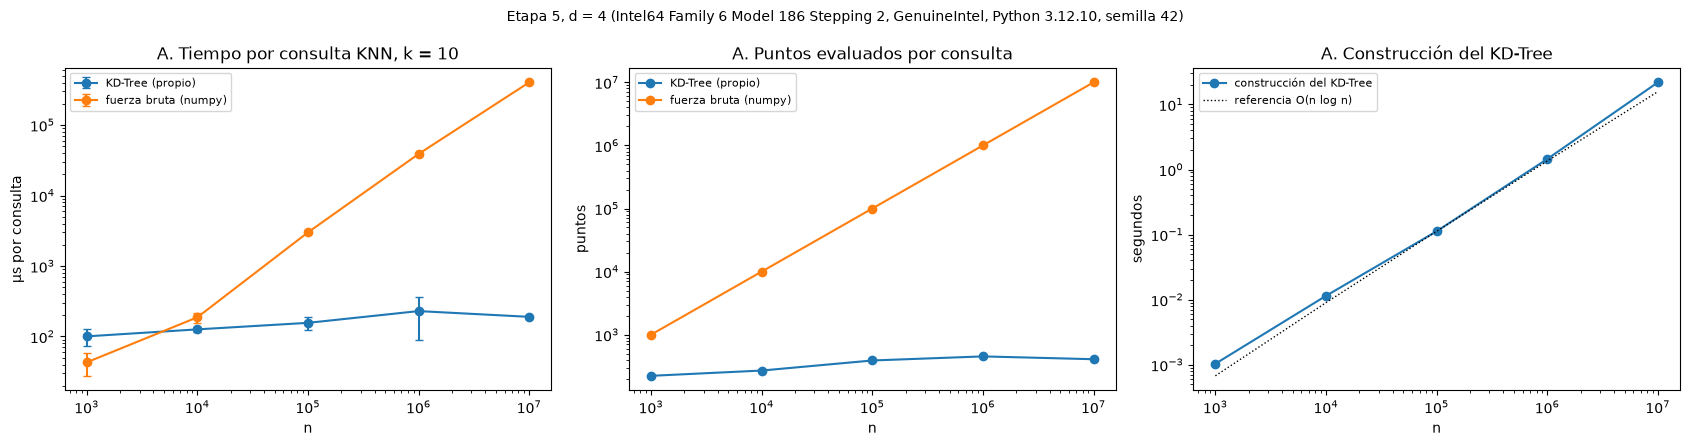

,metodo,n,us_por_consulta,desv_us,puntos_evaluados,construccion_s,altura,repeticiones,fraccion_evaluada
0,KD-Tree (propio),1000,100.4,27.3,223.0,0.001,6.0,100,0.222599
1,KD-Tree (propio),10000,126.2,11.5,270.0,0.011,10.0,100,0.026984
2,KD-Tree (propio),100000,156.2,34.5,390.0,0.112,13.0,20,0.003897
3,KD-Tree (propio),1000000,229.3,139.0,452.0,1.450,16.0,5,0.000452
4,KD-Tree (propio),10000000,190.1,NaN,408.0,21.865,20.0,1,0.000041
5,fuerza bruta (numpy),1000,43.0,15.3,1000.0,NaN,NaN,100,1.000000
6,fuerza bruta (numpy),10000,187.3,31.2,10000.0,NaN,NaN,100,1.000000
7,fuerza bruta (numpy),100000,2999.4,183.8,100000.0,NaN,NaN,20,1.000000
8,fuerza bruta (numpy),1000000,38886.6,1307.4,1000000.0,NaN,NaN,5,1.000000
9,fuerza bruta (numpy),10000000,403434.2,NaN,10000000.0,NaN,NaN,1,1.000000


,metodo,pendiente_empirica,esperado,rango
0,KD-Tree (propio),0.08,≈0 (log n),"1,000 a 10,000,000"
1,fuerza bruta (numpy),1.03,≈1 (n),"1,000 a 10,000,000"


,metodo,pendiente_empirica,esperado,rango
0,construcción del KD-Tree,1.08,≈1-1.1 (n log n),"1,000 a 10,000,000"


In [9]:
ruta_a = CARPETA_RESULTADOS / "etapa5_knn_n.csv"
if ruta_a.exists() and not REEJECUTAR_EXPERIMENTOS:
    tiempos_a = pd.read_csv(ruta_a)
    print(f"Resultados leídos de {ruta_a.relative_to(RAIZ)}")
else:
    filas = []
    for n in TAMANOS:
        X = datos_remuestreados(n)
        rng = np.random.default_rng(SEED + n)
        construccion = []
        for rep in range(min(REPETICIONES[n], 5)):
            resultado = {}
            construccion.append(medir(lambda: resultado.update(arbol=KDTree(X))))
        arbol = resultado["arbol"]
        for rep in range(REPETICIONES[n]):
            consultas = X[rng.integers(0, n, size=CONSULTAS_POR_REPETICION)]
            t_kd, t_fb, evaluados = medir_consultas(arbol, X, consultas, K)
            filas.append({"metodo": "KD-Tree (propio)", "n": n, "repeticion": rep, "segundos": t_kd,
                          "puntos_evaluados": evaluados, "construccion_s": np.mean(construccion),
                          "construccion_desv_s": np.std(construccion), "altura": arbol.altura()})
            filas.append({"metodo": "fuerza bruta (numpy)", "n": n, "repeticion": rep, "segundos": t_fb,
                          "puntos_evaluados": n})
        del X, arbol, resultado
        print(f"n = {n:>10,} medido")
    tiempos_a = pd.DataFrame(filas)
    tiempos_a.to_csv(ruta_a, index=False)
    print(f"Resultados guardados en {ruta_a.relative_to(RAIZ)}")

tiempos_a["us_por_consulta"] = tiempos_a["segundos"] / CONSULTAS_POR_REPETICION * 1e6
resumen_a = (tiempos_a.groupby(["metodo", "n"])
             .agg(us_por_consulta=("us_por_consulta", "mean"), desv_us=("us_por_consulta", "std"),
                  puntos_evaluados=("puntos_evaluados", "mean"), construccion_s=("construccion_s", "first"),
                  altura=("altura", "first"), repeticiones=("segundos", "count"))
             .reset_index())
resumen_a["fraccion_evaluada"] = resumen_a["puntos_evaluados"] / resumen_a["n"]

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.5))
for nombre, datos in resumen_a.groupby("metodo"):
    ax1.errorbar(datos["n"], datos["us_por_consulta"], yerr=datos["desv_us"], marker="o", capsize=3, label=nombre)
    ax2.plot(datos["n"], datos["puntos_evaluados"], marker="o", label=nombre)
kd_a = resumen_a.query("metodo == 'KD-Tree (propio)'")
n_ref = np.array(TAMANOS, dtype=float)
ax3.plot(kd_a["n"], kd_a["construccion_s"], marker="o", label="construcción del KD-Tree")
ax3.plot(n_ref, kd_a["construccion_s"].iloc[2] * (n_ref * np.log2(n_ref)) / (1e5 * np.log2(1e5)), "k:", lw=1,
         label="referencia O(n log n)")
for ax, titulo, ylabel in [(ax1, "A. Tiempo por consulta KNN, k = 10", "µs por consulta"),
                           (ax2, "A. Puntos evaluados por consulta", "puntos"),
                           (ax3, "A. Construcción del KD-Tree", "segundos")]:
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n"); ax.set_ylabel(ylabel); ax.set_title(titulo); ax.legend(fontsize=8)
plt.suptitle(f"Etapa 5, d = 4 ({PLATAFORMA['procesador']}, Python {PLATAFORMA['python']}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa5_knn_n.png", dpi=150)
plt.show()

display(resumen_a.round({"us_por_consulta": 1, "desv_us": 1, "puntos_evaluados": 0, "construccion_s": 3,
                         "fraccion_evaluada": 6}))
display(pendientes(resumen_a, "us_por_consulta", {"KD-Tree (propio)": "≈0 (log n)", "fuerza bruta (numpy)": "≈1 (n)"}))
pendientes(kd_a.assign(metodo="construcción del KD-Tree"), "construccion_s", {"construcción del KD-Tree": "≈1-1.1 (n log n)"})

### Experimento B. KNN según la dimensión

Con n = 100 000 puntos uniformes se varía la dimensión entre 2 y 32. Se espera que la fracción de puntos que evalúa el KD-Tree crezca rápido con d. Con d alto, la distancia al vecino más cercano se parece a la distancia a cualquier punto, la poda deja de descartar regiones y el KD-Tree evalúa casi todos los puntos (Weber, Schek y Blott, 1998). Ese es el motivo por el que la etapa 7 usa búsqueda aproximada para vectores de dimensión alta. Cada dimensión se mide con 5 repeticiones de 100 consultas.

Resultados leídos de results\etapa5_knn_dimension.csv


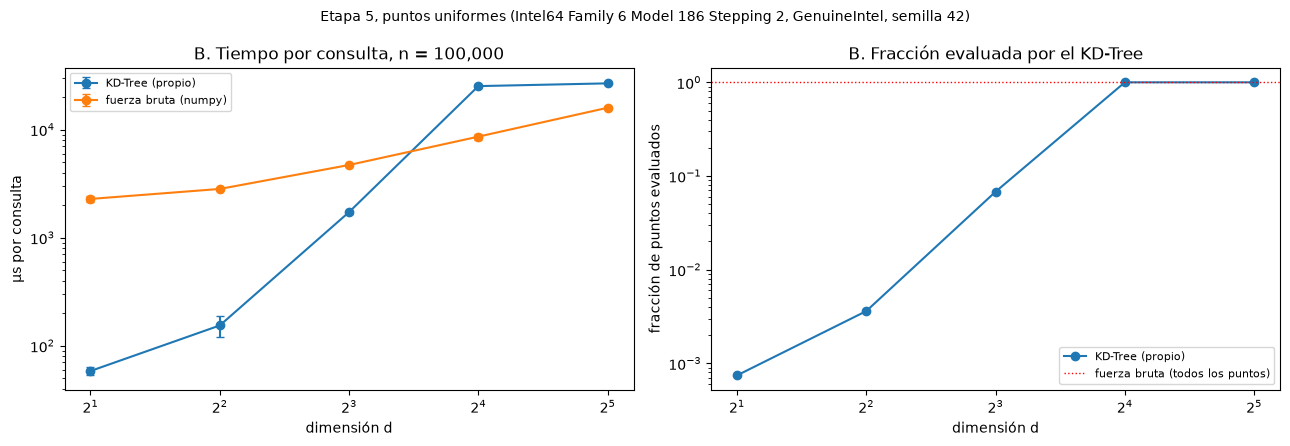

,metodo,d,us_por_consulta,desv_us,puntos_evaluados,repeticiones,fraccion_evaluada
0,KD-Tree (propio),2,58.3,5.2,74.0,5,0.0007
1,KD-Tree (propio),4,154.0,34.5,361.0,5,0.0036
2,KD-Tree (propio),8,1723.0,58.7,6789.0,5,0.0679
3,KD-Tree (propio),16,25232.1,1005.6,99999.0,5,1.0000
4,KD-Tree (propio),32,26757.2,595.8,100000.0,5,1.0000
5,fuerza bruta (numpy),2,2281.0,135.6,100000.0,5,1.0000
6,fuerza bruta (numpy),4,2822.0,85.5,100000.0,5,1.0000
7,fuerza bruta (numpy),8,4699.9,50.6,100000.0,5,1.0000
8,fuerza bruta (numpy),16,8599.7,578.6,100000.0,5,1.0000
9,fuerza bruta (numpy),32,15914.6,493.4,100000.0,5,1.0000


In [10]:
DIMENSIONES = [2, 4, 8, 16, 32]
N_DIMENSION = 100_000
REPETICIONES_B = 5

ruta_b = CARPETA_RESULTADOS / "etapa5_knn_dimension.csv"
if ruta_b.exists() and not REEJECUTAR_EXPERIMENTOS:
    tiempos_b = pd.read_csv(ruta_b)
    print(f"Resultados leídos de {ruta_b.relative_to(RAIZ)}")
else:
    filas = []
    for d in DIMENSIONES:
        rng = np.random.default_rng(SEED + d)
        X = rng.uniform(size=(N_DIMENSION, d))
        arbol = KDTree(X)
        for rep in range(REPETICIONES_B):
            consultas = X[rng.integers(0, N_DIMENSION, size=CONSULTAS_POR_REPETICION)]
            t_kd, t_fb, evaluados = medir_consultas(arbol, X, consultas, K)
            filas.append({"metodo": "KD-Tree (propio)", "d": d, "repeticion": rep, "segundos": t_kd,
                          "puntos_evaluados": evaluados})
            filas.append({"metodo": "fuerza bruta (numpy)", "d": d, "repeticion": rep, "segundos": t_fb,
                          "puntos_evaluados": N_DIMENSION})
        print(f"d = {d:>2} medido")
    tiempos_b = pd.DataFrame(filas)
    tiempos_b.to_csv(ruta_b, index=False)
    print(f"Resultados guardados en {ruta_b.relative_to(RAIZ)}")

tiempos_b["us_por_consulta"] = tiempos_b["segundos"] / CONSULTAS_POR_REPETICION * 1e6
resumen_b = (tiempos_b.groupby(["metodo", "d"])
             .agg(us_por_consulta=("us_por_consulta", "mean"), desv_us=("us_por_consulta", "std"),
                  puntos_evaluados=("puntos_evaluados", "mean"), repeticiones=("segundos", "count"))
             .reset_index())
resumen_b["fraccion_evaluada"] = resumen_b["puntos_evaluados"] / N_DIMENSION

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, datos in resumen_b.groupby("metodo"):
    ax1.errorbar(datos["d"], datos["us_por_consulta"], yerr=datos["desv_us"], marker="o", capsize=3, label=nombre)
kd_b = resumen_b.query("metodo == 'KD-Tree (propio)'")
ax2.plot(kd_b["d"], kd_b["fraccion_evaluada"], marker="o", label="KD-Tree (propio)")
ax2.axhline(1.0, color="r", ls=":", lw=1, label="fuerza bruta (todos los puntos)")
ax1.set_yscale("log"); ax1.set_ylabel("µs por consulta"); ax1.set_title(f"B. Tiempo por consulta, n = {N_DIMENSION:,}")
ax2.set_yscale("log"); ax2.set_ylabel("fracción de puntos evaluados"); ax2.set_title("B. Fracción evaluada por el KD-Tree")
for ax in (ax1, ax2):
    ax.set_xscale("log", base=2); ax.set_xlabel("dimensión d"); ax.legend(fontsize=8)
plt.suptitle(f"Etapa 5, puntos uniformes ({PLATAFORMA['procesador']}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa5_knn_dimension.png", dpi=150)
plt.show()

resumen_b.round({"us_por_consulta": 1, "desv_us": 1, "puntos_evaluados": 0, "fraccion_evaluada": 4})

### Experimento C. KNN según k

Con n = 1M puntos remuestreados se varía k entre 1 y 1 000. El KD-Tree debe evaluar más puntos a medida que crece k, porque el radio del k-ésimo vecino es mayor y la poda descarta menos. La fuerza bruta calcula siempre las n distancias y solo cambia el costo de seleccionar los k menores. Cada valor de k se mide con 5 repeticiones de 100 consultas.

k =     1 medido


k =    10 medido


k =   100 medido


k = 1,000 medido
Resultados guardados en results\etapa5_knn_k.csv


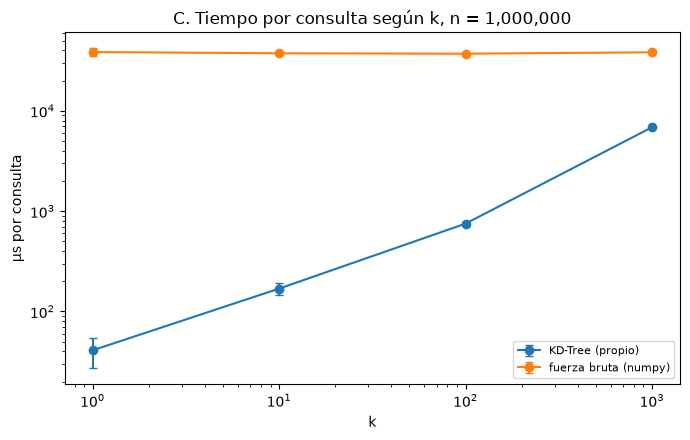

,metodo,k,us_por_consulta,desv_us,puntos_evaluados,repeticiones
0,KD-Tree (propio),1,41.0,13.7,31.0,5
1,KD-Tree (propio),10,168.8,21.3,467.0,5
2,KD-Tree (propio),100,750.9,32.7,1778.0,5
3,KD-Tree (propio),1000,6866.3,184.3,9116.0,5
4,fuerza bruta (numpy),1,38602.6,3443.2,1000000.0,5
5,fuerza bruta (numpy),10,37501.2,959.0,1000000.0,5
6,fuerza bruta (numpy),100,37175.3,579.5,1000000.0,5
7,fuerza bruta (numpy),1000,38364.8,1245.6,1000000.0,5


,metodo,pendiente_empirica,esperado,rango
0,KD-Tree (propio),0.73,creciente con k,"1 a 1,000"
1,fuerza bruta (numpy),-0.00,≈0,"1 a 1,000"


In [11]:
VALORES_K = [1, 10, 100, 1_000]
N_K = 1_000_000
REPETICIONES_C = 5

ruta_c = CARPETA_RESULTADOS / "etapa5_knn_k.csv"
if ruta_c.exists() and not REEJECUTAR_EXPERIMENTOS:
    tiempos_c = pd.read_csv(ruta_c)
    print(f"Resultados leídos de {ruta_c.relative_to(RAIZ)}")
else:
    filas = []
    X = datos_remuestreados(N_K)
    arbol = KDTree(X)
    rng = np.random.default_rng(SEED)
    for k in VALORES_K:
        for rep in range(REPETICIONES_C):
            consultas = X[rng.integers(0, N_K, size=CONSULTAS_POR_REPETICION)]
            t_kd, t_fb, evaluados = medir_consultas(arbol, X, consultas, k)
            filas.append({"metodo": "KD-Tree (propio)", "k": k, "repeticion": rep, "segundos": t_kd,
                          "puntos_evaluados": evaluados})
            filas.append({"metodo": "fuerza bruta (numpy)", "k": k, "repeticion": rep, "segundos": t_fb,
                          "puntos_evaluados": N_K})
        print(f"k = {k:>5,} medido")
    del X, arbol
    tiempos_c = pd.DataFrame(filas)
    tiempos_c.to_csv(ruta_c, index=False)
    print(f"Resultados guardados en {ruta_c.relative_to(RAIZ)}")

tiempos_c["us_por_consulta"] = tiempos_c["segundos"] / CONSULTAS_POR_REPETICION * 1e6
resumen_c = (tiempos_c.groupby(["metodo", "k"])
             .agg(us_por_consulta=("us_por_consulta", "mean"), desv_us=("us_por_consulta", "std"),
                  puntos_evaluados=("puntos_evaluados", "mean"), repeticiones=("segundos", "count"))
             .reset_index())

fig, ax = plt.subplots(figsize=(7, 4.5))
for nombre, datos in resumen_c.groupby("metodo"):
    ax.errorbar(datos["k"], datos["us_por_consulta"], yerr=datos["desv_us"], marker="o", capsize=3, label=nombre)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("k"); ax.set_ylabel("µs por consulta"); ax.set_title(f"C. Tiempo por consulta según k, n = {N_K:,}")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa5_knn_k.png", dpi=150)
plt.show()

display(resumen_c.round({"us_por_consulta": 1, "desv_us": 1, "puntos_evaluados": 0}))
pendientes(resumen_c, "us_por_consulta", {"KD-Tree (propio)": "creciente con k", "fuerza bruta (numpy)": "≈0"}, x="k")

### Memoria

Se mide con `tracemalloc` la memoria del KD-Tree construido sobre n puntos remuestreados, sin contar la matriz original. Incluye la copia reordenada de los puntos, la permutación y las listas de nodos. La fuerza bruta no tiene estructura adicional y solo usa la matriz de puntos, de 8 · d bytes por punto.

In [12]:
ruta_memoria = CARPETA_RESULTADOS / "etapa5_memoria.csv"
if ruta_memoria.exists() and not REEJECUTAR_EXPERIMENTOS:
    memoria = pd.read_csv(ruta_memoria)
else:
    filas = []
    for n in [1_000, 10_000, 100_000, 1_000_000]:
        X = datos_remuestreados(n)
        gc.collect()
        tracemalloc.start()
        arbol = KDTree(X)
        actual, pico = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        filas.append({"n": n, "nodos": arbol.n_nodos, "kdtree_mb": actual / 1e6, "pico_construccion_mb": pico / 1e6,
                      "matriz_mb": X.nbytes / 1e6})
        del X, arbol
    memoria = pd.DataFrame(filas)
    memoria.to_csv(ruta_memoria, index=False)

memoria["kdtree_bytes_por_punto"] = memoria["kdtree_mb"] * 1e6 / memoria["n"]
memoria.round(3)

,n,nodos,kdtree_mb,pico_construccion_mb,matriz_mb,kdtree_bytes_por_punto
0,1000,63,0.055,0.108,0.032,54.504
1,10000,1023,0.530,1.017,0.320,52.965
2,100000,8191,4.996,9.804,3.200,49.962
3,1000000,65535,48.098,96.107,32.000,48.098


### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada en `results/`. Al medir de nuevo pueden variar ligeramente.

- **Índice real.** Con 336 415 productos de 607 categorías, el KD-Tree global tiene 32 737 nodos y altura 15 y se construye en 1.4 s. La altura corresponde a las ⌈log₂(n / 32)⌉ = 14 divisiones por la mitad que llevan a hojas de 32 puntos o menos, más el nivel de las hojas. En 3 000 consultas reales, sin filtro, con filtro y con el árbol de la categoría, los resultados coincidieron con la fuerza bruta. La consulta por caja evaluó 8 700 puntos y tardó 3.4 ms. El B+Tree de la etapa 4 más un filtro dio los mismos 4 195 productos en 171 ms, porque primero recupera los 100 715 productos del rango de precio.
- **Árbol por categoría.** Buscar vecinos dentro de la categoría con el filtro sobre el árbol global tardó en promedio 7.9 ms, y con el árbol de la categoría 0.20 ms, 40 veces menos. Con el filtro, los productos de una categoría pequeña están dispersos en todo el espacio y la búsqueda recorre muchas hojas hasta reunir 10 de esa categoría. Con el árbol por categoría, los vecinos de los 193 422 productos con actividad se calcularon en 70 s, 0.18 ms por consulta.
- **Experimento A.** El tiempo por consulta del KD-Tree pasa de 100 µs a 1K a 190 µs a 10M, con pendiente 0.08. Evalúa entre 220 y 450 puntos por consulta en todo el rango, lo que equivale al 0.004 % de los puntos a 10M. La fuerza bruta tiene pendiente 1.03 y llega a 403 ms por consulta a 10M, 2 100 veces más que el KD-Tree. Con n = 1K la fuerza bruta es 2.3 veces más rápida, porque numpy calcula 1 000 distancias en C más rápido de lo que Python recorre el árbol. El punto de cruce está cerca de 10K. La construcción tiene pendiente 1.08, coherente con O(n log n), y tarda 22 s con 10M puntos.
- **Experimento B.** Con n = 100K uniformes, el KD-Tree evalúa el 0.07 % de los puntos en d = 2, el 0.36 % en d = 4 y el 6.8 % en d = 8. En d = 16 y d = 32 evalúa todos los puntos, porque la poda ya no descarta ninguna región. Desde d = 16 es entre 1.7 y 3 veces más lento que la fuerza bruta, porque hace el mismo trabajo y además recorre el árbol en Python. Esto confirma la maldición de la dimensión y justifica que la etapa 7 use búsqueda aproximada para vectores de dimensión alta.
- **Experimento C.** El KD-Tree pasa de 31 puntos evaluados con k = 1 a 9 116 con k = 1 000, y su tiempo crece con pendiente 0.73. La fuerza bruta tarda unos 38 ms para cualquier k, porque siempre calcula el millón de distancias. Incluso con k = 1 000 el KD-Tree es 5.6 veces más rápido.
- **Memoria.** El KD-Tree ocupa unos 48 a 55 bytes por punto con d = 4. Unos 32 bytes son la copia reordenada de los puntos y el resto son la permutación y las listas de nodos. El pico durante la construcción es el doble por las copias temporales de numpy. La fuerza bruta solo usa la matriz, de 32 bytes por punto.

El KD-Tree cumple la complejidad esperada en dimensión baja y es la estructura adecuada para los 4 atributos de los productos. La fuerza bruta queda como referencia exacta para los vectores de dimensión alta de la etapa 7.

## Paso 7. Salida de la etapa 5

La etapa produce dos archivos en `data/interim/<CATEGORIA>/`.

| Archivo | Contenido | Etapas que lo usan |
| --- | --- | --- |
| `etapa5_vectores.npz` | `parent_asin`, vectores normalizados, media y desviación de cada atributo, categoría de cada producto | 7 (espacio vectorial de la búsqueda aproximada), 9 |
| `etapa5_vecinos.parquet` | Los 10 vecinos exactos de cada producto con actividad en el stream, en todo el catálogo y dentro de su categoría | 7 (referencia para el recall@K), 9 (productos relacionados) |

Las etapas siguientes también pueden importar `IndiceProductos` desde `src/stage5_kdtree.py` para consultar vecinos en línea.

In [13]:
np.savez_compressed(RUTA_VECTORES, asins=np.array(indice.asins), Z=indice.Z, media=indice.media, desv=indice.desv,
                    atributos=np.array(ATRIBUTOS), categoria=indice.categoria,
                    nombres_categoria=np.array(indice.nombres_categoria))

activos = [a for a in estados["parent_asin"] if indice.posicion.obtener(a) is not None]
filas = []
t0 = time.perf_counter()
for asin in activos:
    for alcance, misma in (("global", False), ("misma_categoria", True)):
        for rango, (distancia, vecino) in enumerate(indice.similares(asin, k=10, misma_categoria=misma), start=1):
            filas.append({"parent_asin": asin, "alcance": alcance, "rango": rango, "vecino": vecino,
                          "distancia": distancia})
t_vecinos = time.perf_counter() - t0
vecinos = pd.DataFrame(filas)
pq.write_table(pa.Table.from_pandas(vecinos, preserve_index=False), RUTA_VECINOS, compression="zstd")

print(f"Vecinos calculados para {len(activos):,} productos en {t_vecinos:.1f} s "
      f"({t_vecinos / (2 * len(activos)) * 1e3:.2f} ms por consulta)")
for ruta in (RUTA_VECTORES, RUTA_VECINOS):
    print(f"{ruta.relative_to(RAIZ)}: {ruta.stat().st_size / 1e6:,.1f} MB")
vecinos.head(12)

Vecinos calculados para 193,422 productos en 70.3 s (0.18 ms por consulta)
data\interim\Office_Products\etapa5_vectores.npz: 5.4 MB
data\interim\Office_Products\etapa5_vecinos.parquet: 52.5 MB


,parent_asin,alcance,rango,vecino,distancia
0,B00LRUXN42,global,1,B0BWXX6J6C,0.053327
1,B00LRUXN42,global,2,B01HQPKQSM,0.067548
2,B00LRUXN42,global,3,B0C6QG9Q71,0.081423
3,B00LRUXN42,global,4,B006BYRJ4Y,0.087434
4,B00LRUXN42,global,5,B004E2OHUE,0.087485
5,B00LRUXN42,global,6,B08ZLPRJQL,0.092431
6,B00LRUXN42,global,7,B07WXMM57L,0.094621
7,B00LRUXN42,global,8,1469393352,0.094765
8,B00LRUXN42,global,9,B071RVNC4K,0.101138
9,B00LRUXN42,global,10,B0971PBWCD,0.106255


## Resumen de la etapa 5

| Aspecto | Decisión |
| --- | --- |
| Estructura | KD-Tree propio con corte por la mediana de la dimensión de mayor dispersión y hojas de hasta 32 puntos |
| Por qué KD-Tree | Puntos (no objetos con extensión), dimensión baja (d = 4) y conjunto casi estático |
| Vectores | log del precio, calificación, log del número de calificaciones y log de la actividad en el stream, normalizados con z-score |
| Entrada | Recorrido del B+Tree de la etapa 4, catálogo y estado del stream de la etapa 3 |
| Consultas | KNN exacto global y dentro de la categoría con un KD-Tree por categoría (k mejores en el `MinHeap` de la etapa 2) y rango multidimensional |
| Línea base | KNN por fuerza bruta con numpy, también usado como referencia de la etapa 7 |
| Salida | Vectores y 10 vecinos exactos por producto activo en `data/interim/<CATEGORIA>/` |

Referencias. Bentley, J. L. (1975). Multidimensional binary search trees used for associative searching. *Communications of the ACM*, 18(9), 509-517. Friedman, J. H., Bentley, J. L., y Finkel, R. A. (1977). An algorithm for finding best matches in logarithmic expected time. *ACM Transactions on Mathematical Software*, 3(3), 209-226. Guttman, A. (1984). R-trees: A dynamic index structure for spatial searching. *Proceedings of ACM SIGMOD*, 47-57. Weber, R., Schek, H.-J., y Blott, S. (1998). A quantitative analysis and performance study for similarity-search methods in high-dimensional spaces. *Proceedings of VLDB*, 194-205. Samet, H. (2006). *Foundations of Multidimensional and Metric Data Structures*. Morgan Kaufmann.